# Рабочая тетрадь № 3. Примеры

Примеры из разделов 1.1–1.2, 2.2 и 3.2. Ячейки запускаются сверху вниз.

## 1. Функции и расстояние между объектами

### 1.1. Функции Python

Функция задаётся инструкцией `def` и возвращает значение через `return`. Без `return` функция возвращает `None`. `*args` собирает позиционные аргументы в кортеж, `**kwargs` — именованные в словарь.

In [1]:
def add(x, y):
    return x + y

print(add(1, 10))
print(add('abc', 'def'))


def newfunc(n):
    def myfunc(x):
        return x + n
    return myfunc

new = newfunc(100)  # new - это функция
print(new(200))


def func():
    pass

print(func())


def func(*args):
    return args

print(func(1, 2, 3, 'abc'))
print(func())
print(func(1))


def func(**kwargs):
    return kwargs

print(func(a=1, b=2, c=3))
print(func())
print(func(a='python'))

11
abcdef
300
None
(1, 2, 3, 'abc')
()
(1,)
{'a': 1, 'b': 2, 'c': 3}
{}
{'a': 'python'}


### Пример 1.2.1

Напишите функцию `sum_range(start, end)`, которая суммирует все целые числа от значения `start` до величины `end` включительно. Если пользователь задаст первое число большее, чем второе, поменяйте их местами.

In [2]:
def sum_range(start, end):
    if start > end:
        end, start = start, end
    return sum(range(start, end + 1))

# Тесты
print(sum_range(2, 12))
print(sum_range(-4, 4))
print(sum_range(3, 2))

77
0
5


### Пример 1.2.2

Напишите рекурсивную функцию вычисления факториала на языке Python.

In [3]:
def fact(num):
    if num == 0:
        return 1  # По договоренности факториал нуля равен единице
    else:
        return num * fact(num - 1)
    # Возвращаем результат произведения num и результата возвращенного функцией fact(num - 1)
print(fact(5))

120


### Пример 1.2.3

Напишите функцию в Python, которая вычисляет евклидово расстояние между двумя массивами NumPy.

In [4]:
import numpy as np
def euclidean_distance(v1, v2):
    return sum((x - y) ** 2 for x, y in zip(v1, v2)) ** 0.5

x = np.array([0,0,0])
y = np.array([3,3,3])
print(euclidean_distance(x,y))

5.196152422706632


### Пример 1.2.4

Напишите 4 функции в Python, которые рассчитывают квадрат евклидова расстояния, взвешенное евклидово расстояние, хеммингово расстояние и расстояние Чебышева между двумя массивами NumPy.

In [5]:
def sqr_euclidean_distance(v1, v2):
    return sum((x - y) ** 2 for x, y in zip(v1, v2))

def weighted_euclidean_distance(v1, v2, w):
    return sum((x - y) ** 2 * s for x, y, s in zip(v1, v2, w)) ** 0.5

def manhattan_distance(v1, v2):
    return sum(abs(x - y) for (x, y) in zip(v1, v2))

def chebyshev_distance(v1, v2):
    return max(abs(x - y) for (x, y) in zip(v1, v2))

x = np.array([0,0,0])
y = np.array([3,3,3])
w = np.array([0,0,1])
print(sqr_euclidean_distance(x,y))
print(weighted_euclidean_distance(x,y,w))
print(manhattan_distance(x,y))
print(chebyshev_distance(x,y))

27
3.0
9
3


### Пример 1.2.5

Две точки в трёхмерном пространстве для дальнейших расчётов. Ряд pandas переводится в массив NumPy методом `seriesName.to_numpy()`.

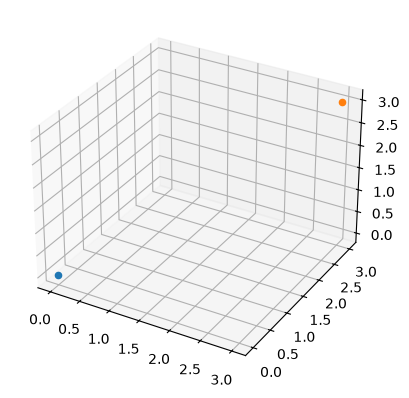

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure()
ax = fig.add_subplot(111, projection = '3d')

ax.scatter(0, 0, 0)
ax.scatter(3, 3, 3)
plt.show()

### Пример 1.2.6

Рассчитать расстояния между двумя точками с использованием методов определения расстояний, представленных выше.

В тетради `p1` и `p2` используются в формулах, но не создаются. Это те же точки, что `x` и `y` выше: ответы 5.196…, 27.0, 3.0 и 9.0 получаются именно для `(0, 0, 0)` и `(3, 3, 3)`.

In [7]:
p1 = x
p2 = y
#Расстояние Евклида
print(np.linalg.norm(x-y))
#Квадрат Евклидова расстояния
print(np.linalg.norm(x-y) ** 2)
#Расстояние Чебышева
print(np.linalg.norm(p1-p2, ord=np.inf))
#Расстояние Хемминга
print(np.linalg.norm(p1-p2,ord=1))

5.196152422706632
27.0
3.0
9.0


## 2. Метод k ближайших соседей

Классификатор относит объект к классу, который чаще встречается среди k ближайших соседей.

### Пример 2.2.1

Создаётся 2d-массив со значениями x и y. Список `target` содержит выходные классы. Классификатор k ближайших соседей обучается на этих данных и предсказывает класс двух точек.

In [8]:
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

# данные
X = np.array([[-1, -1], [-2, -1], [-3, -2], [1, 1], [2, 1], [3, 2]])
target = [0, 0, 0, 1, 1, 1]

# обучаем модель k-ближайших соседей к данным
K = 3
model = KNeighborsClassifier(n_neighbors = K)
model.fit(X, target)
print(model)

# делаем прогноз
print( '(-2,-2) is class'),
print( model.predict([[-2,-2]]) )

print( '(1,3) is class'),
print( model.predict([[1,3]]) )

KNeighborsClassifier(n_neighbors=3)
(-2,-2) is class
[0]
(1,3) is class
[1]


### Пример 2.2.2

Набор данных ирисов Фишера из seaborn: 150 цветков, в столбцах длина и ширина чашелистика, длина и ширина лепестка, вид ириса.

In [9]:
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns

iris = sns.load_dataset('iris')
iris

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


### Пример 2.2.3

Графики зависимости ширины лепестка от его длины и длины чашелистика от его ширины. Разные виды цветков отмечены разными цветами.

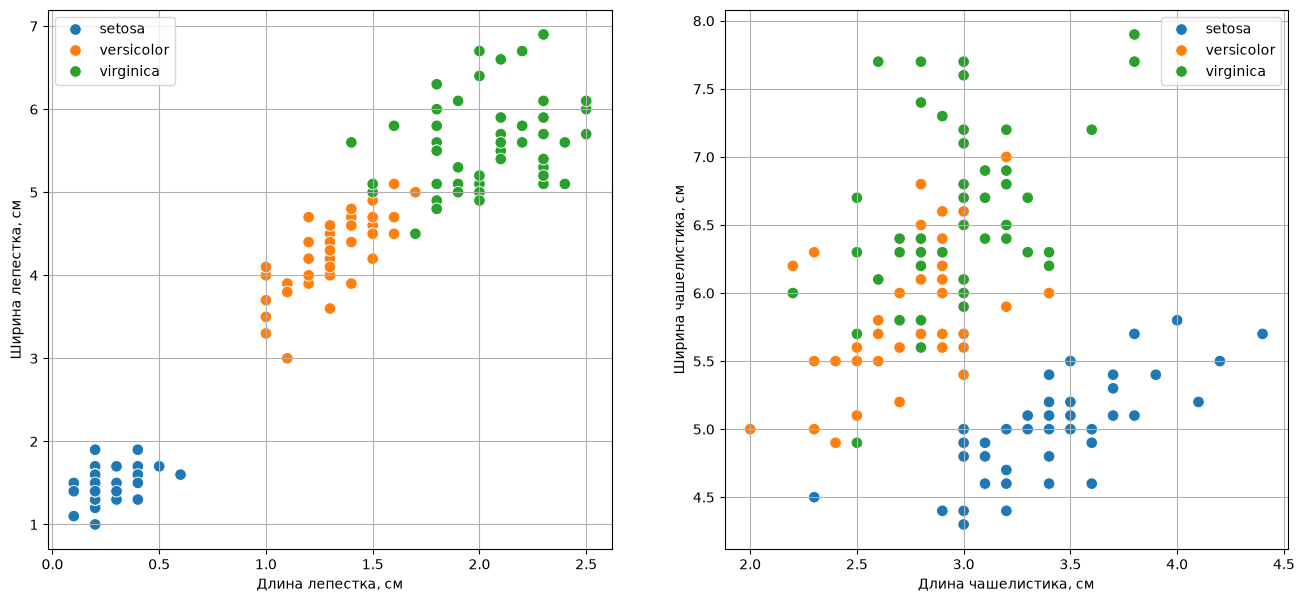

In [10]:
# Объявляем фигуру из двух графиков и ее размер
plt.figure(figsize=(16, 7))

# Левый график
plt.subplot(121)
sns.scatterplot(
    data=iris,  # из этой таблицы нарисовать точки
    x='petal_width', y='petal_length',  # с этими координатами,
    hue='species',  # для которых цвет определить согласно этому столбцу
    s=70  # размер точек
)
plt.xlabel('Длина лепестка, см')
plt.ylabel('Ширина лепестка, см')
plt.legend()  # добавить легенду
plt.grid()  # добавить сетку

# Правый график аналогично
plt.subplot(122)
sns.scatterplot(data=iris, x='sepal_width', y='sepal_length', hue='species', s=70)
plt.xlabel('Длина чашелистика, см')
plt.ylabel('Ширина чашелистика, см')
plt.legend()
plt.grid();

### Пример 2.2.4

По лепестку классы визуально хорошо отделимы, по чашелистику — хуже. Датасет делится на обучающую и тестовую выборки 80:20.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    # поскольку iris это pandas-таблица, для нее нужно указывать iloc
    iris.iloc[:, :-1],  # берем все колонки кроме последней в признаки
    iris.iloc[:, -1],  # последнюю в целевую переменную (класс)
    test_size = 0.20  # размер тестовой выборки 20%
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

In [12]:
X_train.head()

,sepal_length,sepal_width,petal_length,petal_width
121,5.6,2.8,4.9,2.0
122,7.7,2.8,6.7,2.0
136,6.3,3.4,5.6,2.4
145,6.7,3.0,5.2,2.3
67,5.8,2.7,4.1,1.0


In [13]:
y_train.head()

121     virginica
122     virginica
136     virginica
145     virginica
67     versicolor
Name: species, dtype: str

In [14]:
#Обучим метод трех ближайших соседей
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['setosa','versicolor','virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [15]:
#Получим предсказания модели
y_pred = model.predict(X_test)
y_pred

array(['virginica', 'setosa', 'versicolor', 'virginica', 'virginica',
       'versicolor', 'setosa', 'virginica', 'setosa', 'setosa',
       'versicolor', 'versicolor', 'versicolor', 'virginica', 'setosa',
       'setosa', 'virginica', 'versicolor', 'setosa', 'virginica',
       'versicolor', 'virginica', 'virginica', 'virginica', 'setosa',
       'virginica', 'setosa', 'versicolor', 'setosa', 'versicolor'],
      dtype=object)

accuracy: 0.967


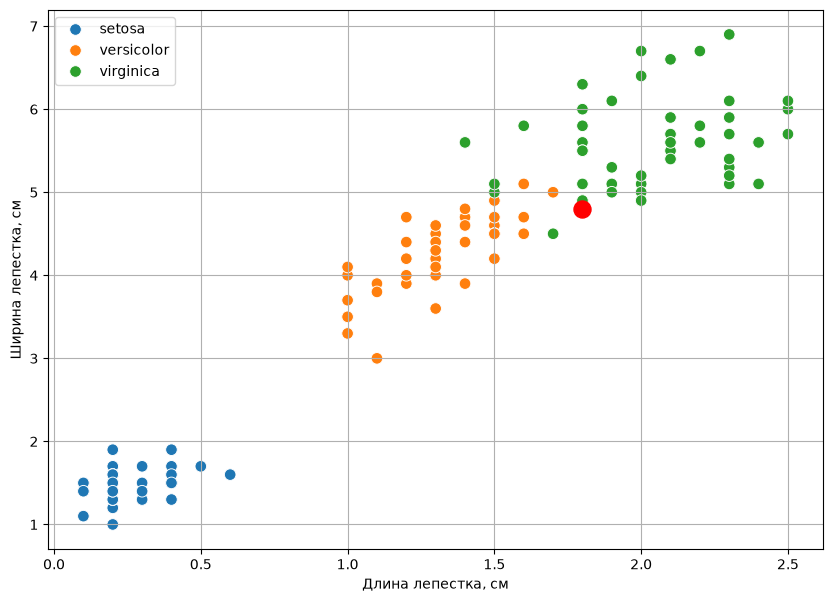

In [16]:
# Покажем на графике, что отражает полученное число.
# Красным цветом обозначены точки, для которых классификация сработала неправильно.
plt.figure(figsize=(10, 7))
sns.scatterplot(x='petal_width', y='petal_length', data=iris, hue='species', s=70)
plt.xlabel('Длина лепестка, см')
plt.ylabel('Ширина лепестка, см')
plt.legend(loc=2)
plt.grid()

# Перебираем все объекты из теста
for i in range(len(y_test)):
    # Если предсказание неправильное
    if np.array(y_test)[i] != y_pred[i]:
        # то подсвечиваем точку красным
        plt.scatter(X_test.iloc[i, 3], X_test.iloc[i, 2], color='red', s=150)

#качество модели (доля правильно классифицированных точек)
from sklearn.metrics import accuracy_score
print(f'accuracy: {accuracy_score(y_test, y_pred) :.3}')

## 3. Категориальные признаки

Порядковые категории (низкая, средняя, высокая) можно заменить числами. Номинальные (цвет) порядка не имеют, их разворачивают в матрицу признаков.

### Пример 3.2.1

Дан порядковый категориальный признак (например, высокий, средний, низкий). Выполнить его кодировку методом `replace`.

In [17]:
# Загрузить библиотеку
import pandas as pd
# Создать признаки
dataframe = pd.DataFrame({"оценка": ["низкая", "низкая", "средняя", "средняя", "высокая"]})
# Создать словарь преобразования шкалы
scale_mapper = {"низкая":1, "средняя":2, "высокая":3}
# Заменить значения признаков значениями словаря
dataframe["оценка"].replace(scale_mapper)

0    1
1    1
2    2
3    2
4    3
Name: оценка, dtype: object

### Пример 3.2.2

Дан словарь, и требуется его конвертировать в матрицу признаков классом `DictVectorizer`.

In [18]:
# Импортировать библиотеку
from sklearn.feature_extraction import DictVectorizer
# Создать словарь
data_dict = [{"красный": 2, "синий": 4},
             {"красный": 4, "синий": 3},
             {"красный": 1, "желтый": 2},
             {"красный": 2, "желтый": 2}]
# Создать векторизатор словаря
dictvectorizer = DictVectorizer(sparse=False)
# Конвертировать словарь в матрицу признаков
features = dictvectorizer.fit_transform(data_dict)
features

array([[0., 2., 4.],
       [0., 4., 3.],
       [2., 1., 0.],
       [2., 2., 0.]])